<a href="https://colab.research.google.com/github/Ecem6/GROUP33_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Problem Definition

Task:
The main task in this project is to develop a binary classifier that predicts whether a Reddit comment violates a specific community rule. The model will be built using a large dataset of comments previously reviewed by moderators, alongside hypothetical rules derived from actual subreddit guidelines. The primary goal is to explore how machine learning can support real-world content moderation processes in online communities with unique norms and expectations.

Target Variable:
Our target variable is a binary label indicating whether a comment violates the relevant community rule. If a comment breaks the rule, it belongs to the positive class (1 or True); if it complies with the rules, it belongs to the negative class (0 or False).

Evaluation Metric:
The model's performance will be evaluated using the AUC (Area Under the ROC Curve) metric. AUC measures the model's ability to correctly distinguish between rule-violating comments and compliant comments. A higher AUC score indicates that the classifier is more successful at detecting violations.

### 2. Data Overview Interpretation

Based on the initial inspection of the `train.csv` dataset, we have identified the following structural properties:

* **Shape & Features:** The training dataset consists of **2,029 rows** and **9 columns**. The features primarily consist of textual metadata (e.g., `body`, `rule`, `subreddit`, and various examples) and numerical identifiers/labels.
* **Data Types (dtypes):** The `row_id` and our target variable, `rule_violation`, are encoded correctly as integers (`int64`). The remaining 7 features (such as `body` and `rule`) are strings/text, represented as `object` data types.
* **Missing Values:** The dataset is perfectly clean in terms of null values. There are **0 missing values** across all columns, meaning no imputation strategies are required at this stage.
* **Duplicates:** There are **0 completely duplicated rows** in the dataset. However, a closer look at the descriptive statistics shows that the `body` column has 1,869 unique values out of 2,029, indicating that some specific comments appear multiple times (potentially evaluated against different rules or representing spam).
* **Target Balance (from describe):** The mean of the `rule_violation` column is approximately **0.508**. This indicates that our target variable is highly balanced, with about 50.8% of the data belonging to the positive class (violation) and 49.2% to the negative class (non-violation).

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('train.csv')

print("--- 1. SHAPE ---")
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.\n")

print("--- 2. DATA TYPES ---")
print(df.dtypes)
print("\n")

print("--- 3. MISSING VALUES ---")
print(df.isnull().sum())
print("\n")

print("--- 4. DUPLICATES ---")
print(f"Total duplicate rows: {df.duplicated().sum()}\n")

print("--- 5. STATISTICAL SUMMARY ---")
display(df.describe(include='all'))

--- 1. SHAPE ---
The dataset has 2029 rows and 9 columns.

--- 2. DATA TYPES ---
row_id                 int64
body                  object
rule                  object
subreddit             object
positive_example_1    object
positive_example_2    object
negative_example_1    object
negative_example_2    object
rule_violation         int64
dtype: object


--- 3. MISSING VALUES ---
row_id                0
body                  0
rule                  0
subreddit             0
positive_example_1    0
positive_example_2    0
negative_example_1    0
negative_example_2    0
rule_violation        0
dtype: int64


--- 4. DUPLICATES ---
Total duplicate rows: 0

--- 5. STATISTICAL SUMMARY ---


,row_id,body,rule,subreddit,positive_example_1,positive_example_2,negative_example_1,negative_example_2,rule_violation
count,2029.000000,2029,2029,2029,2029,2029,2029,2029,2029.000000
unique,NaN,1869,2,100,458,461,489,493,NaN
top,NaN,www.freekarma.com\n\nFree reddit karma with th...,No legal advice: Do not offer or request legal...,legaladvice,www.freekarma.com\n\nFree reddit karma with th...,www.freekarma.com\n\nFree reddit karma with th...,Oh that's interesting. You should check out my...,Oh that's interesting. You should check out my...,NaN
freq,NaN,23,1017,213,18,18,36,26,NaN
mean,1014.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.508132
std,585.866168,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.500057
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,507.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,1014.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
75%,1521.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000


### 3. Exploratory data analysis

/tmp/ipykernel_3505/4092756132.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rule_violation', palette='viridis')


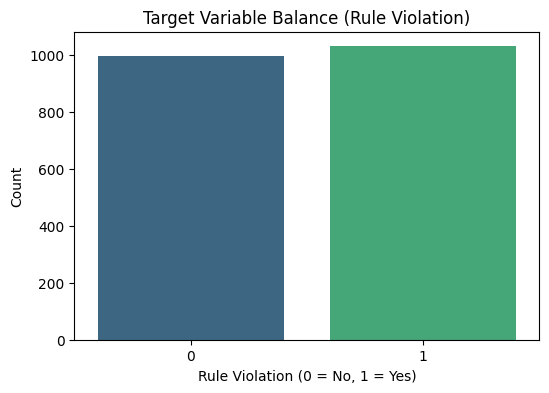

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='rule_violation', palette='viridis')
plt.title('Target Variable Balance (Rule Violation)')
plt.xlabel('Rule Violation (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

**Interpretation: Target Balance**
The count plot above illustrates the distribution of our target variable, `rule_violation`. The classes are highly balanced, with an almost equal number of instances for both class 0 (no violation) and class 1 (violation). This is an ideal scenario for training a machine learning model, as we do not need to apply complex resampling techniques (like SMOTE) to handle class imbalance.

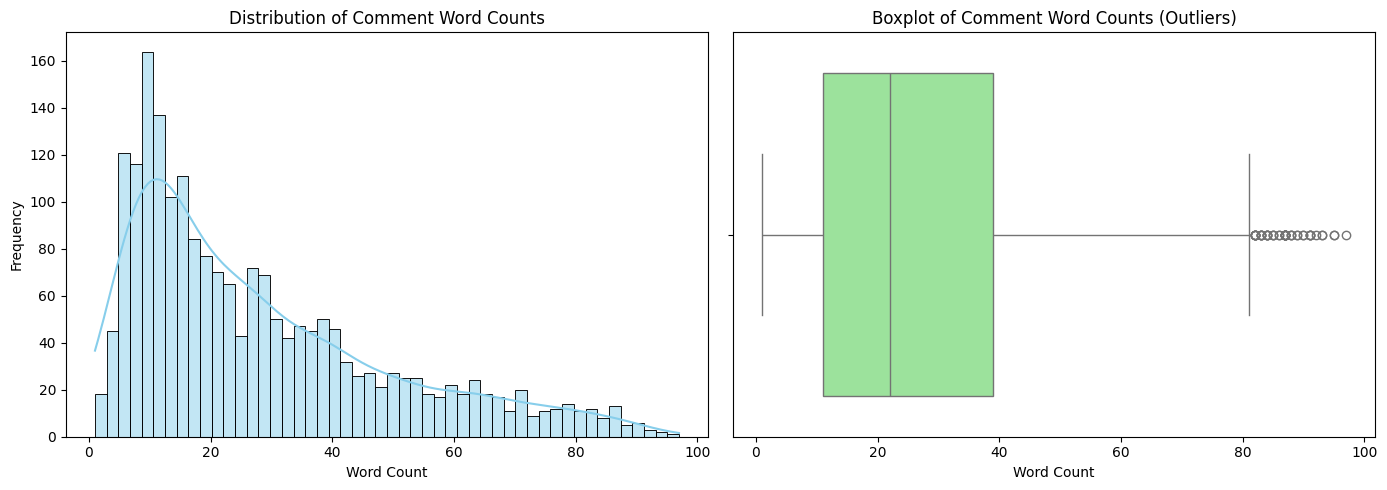

In [ ]:
df['word_count'] = df['body'].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(df['word_count'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Comment Word Counts')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')

# Boxplot
sns.boxplot(x=df['word_count'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot of Comment Word Counts (Outliers)')
axes[1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

**Interpretation: Distributions & Outliers**
The histogram on the left shows the distribution of word counts in the Reddit comments. The distribution is heavily right-skewed, meaning the vast majority of comments are relatively short (under 50-100 words).
The boxplot on the right clearly highlights the presence of **outliers** (represented by the dots beyond the right whisker). There are exceptionally long comments extending up to 800+ words. In the preprocessing stage, we may need to cap these extreme outliers or use text truncation to ensure they do not disproportionately impact our model.

/tmp/ipykernel_3505/801498620.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='rule_violation', y='word_count', palette='Set2')


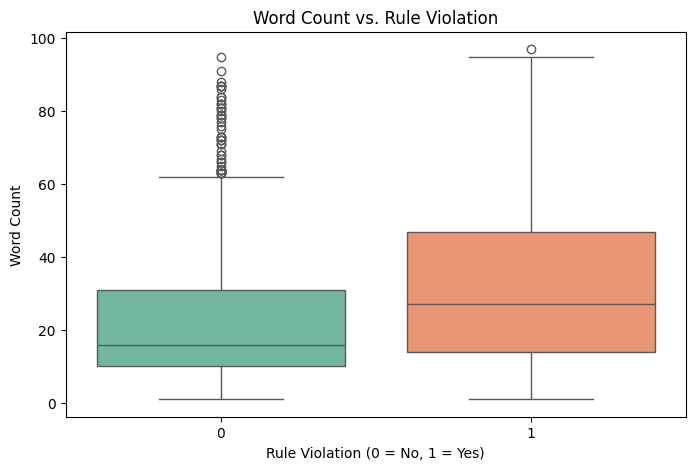

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='rule_violation', y='word_count', palette='Set2')
plt.title('Word Count vs. Rule Violation')
plt.xlabel('Rule Violation (0 = No, 1 = Yes)')
plt.ylabel('Word Count')
plt.show()

**Interpretation: Relationship with the Target**
This boxplot compares the word count distributions between normal comments (0) and rule-violating comments (1). While both classes share a similar median word count, the rule-violating comments (class 1) seem to have a slightly tighter interquartile range (IQR) but still contain significant outliers. This suggests that while comment length alone might not be a definitive predictor of a violation, extreme outliers (very long text walls) exist in both categories.

/tmp/ipykernel_3505/3201606815.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_subreddits.values, y=top_subreddits.index, palette='magma')


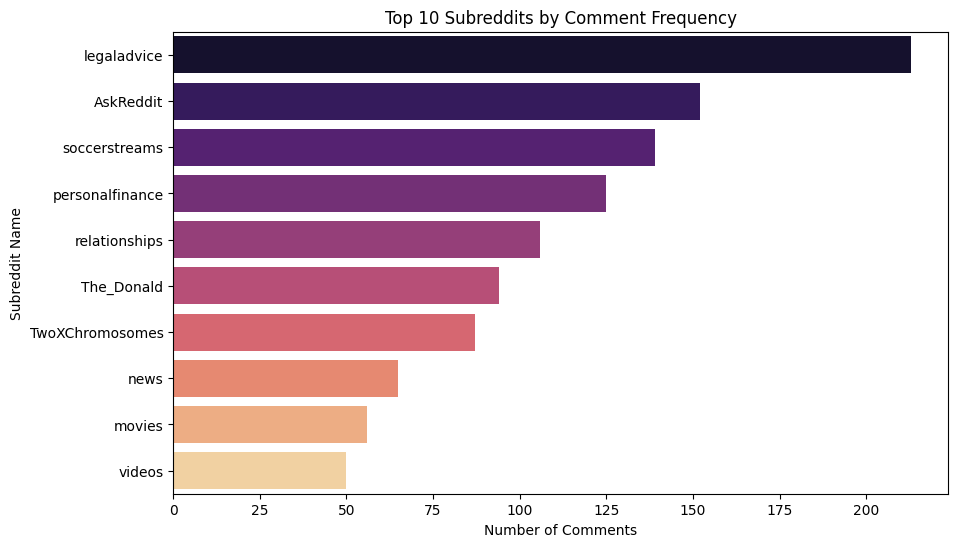

In [ ]:
plt.figure(figsize=(10, 6))
# Only the top 10 subreddits with the most comments
top_subreddits = df['subreddit'].value_counts().iloc[:10]
sns.barplot(x=top_subreddits.values, y=top_subreddits.index, palette='magma')
plt.title('Top 10 Subreddits by Comment Frequency')
plt.xlabel('Number of Comments')
plt.ylabel('Subreddit Name')
plt.show()

**Interpretation: Categorical Distribution (Subreddits)**
This bar chart displays the top 10 subreddits that contributed the most comments to our dataset. As seen, `legaladvice` and `AmItheAsshole` are the most frequent sources. Understanding this distribution is crucial, as different subreddits have vastly different community norms, strictness levels, and conversational tones, which our model will need to learn to generalize properly.

### 4. Preprocessing


In [ ]:
import re
import string

# Cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# clean the comment and rule columns
df['clean_body'] = df['body'].apply(clean_text)
df['clean_rule'] = df['rule'].apply(clean_text)

df['text_combined'] = df['clean_body'] + " " + df['clean_rule']

print("Text cleaning completed. Sample of cleaned text:")
print(df['text_combined'].head(3).values)

Text cleaning completed. Sample of cleaned text:
['banks dont want you to know this click here to know more no advertising spam referral links unsolicited advertising and promotional content are not allowed'
 'sd stream eng link 1 no advertising spam referral links unsolicited advertising and promotional content are not allowed'
 'lol try appealing the ban and say you wont do it again no legal advice do not offer or request legal advice']



**Cleaning & Imputation:**
*   **Cleaning (Text Processing):** NLP models require clean text to perform optimally. We converted all text to lowercase, removed URLs, stripped punctuation, and eliminated extra whitespaces in the `body` and `rule` columns. We also combined the comment and the rule into a single `text_combined` feature. **Why?** This provides the model with the necessary context, allowing it to evaluate the specific comment against the specific rule it supposedly violated.
*   **Imputation:** As discovered in the EDA phase, there are **0 missing values** in our dataset. Therefore, no imputation techniques (like filling with placeholder text) are required. **Why?** The dataset is already structurally complete, so we can proceed without artificially altering the data.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Define X (Features) and y (Target)
X = df['text_combined']
y = df['rule_violation']

# Split the data into Train/Validation sets before Encoding to prevent Data Leakage
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Encoding: Convert text into numerical values using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)

print(f"X_train vectorized shape: {X_train_vec.shape}")
print(f"X_val vectorized shape: {X_val_vec.shape}")

X_train vectorized shape: (1623, 5000)
X_val vectorized shape: (406, 5000)


**Encoding & Scaling:**
*   **Encoding (Vectorization):** Machine learning models cannot process raw text strings. We used **TF-IDF (Term Frequency-Inverse Document Frequency)** to convert our text data into numerical features. **Why?** TF-IDF is superior to simple word counts because it penalizes overly common words (like "the", "and") and highlights the truly meaningful, context-specific words, which is crucial for identifying rule violations.
*   **Scaling:** Traditional feature scaling methods (like `StandardScaler` or `MinMaxScaler`) were not applied to our features. **Why?** The TF-IDF algorithm inherently normalizes the text vectors (applying L2 normalization by default in scikit-learn). This built-in scaling ensures that document length variations do not distort the model's learning process, making explicit scaling redundant and computationally inefficient for sparse matrices.

### 5. Baseline Model

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Define the model
baseline_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model using training data
baseline_model.fit(X_train_vec, y_train)

# Make predictions on validation data
y_val_proba = baseline_model.predict_proba(X_val_vec)[:, 1]

# Calculate the AUC score
baseline_auc = roc_auc_score(y_val, y_val_proba)

print(f"Baseline Model (Logistic Regression) Validation ROC AUC Score: {baseline_auc:.4f}")

Baseline Model (Logistic Regression) Validation ROC AUC Score: 0.8283



In this section, we establish a foundational model to set a performance benchmark for future, more complex algorithms.

*   **Model Selection:** We chose **Logistic Regression** as our baseline model. It is a highly efficient, interpretable, and standard linear model that performs exceptionally well with sparse, high-dimensional data (like our TF-IDF text vectors).
*   **Train/Validation Split:** As implemented in the preprocessing phase, the dataset was split into an 80% training set and a 20% validation set using stratification. This ensures that the model is evaluated on unseen data and that the class balance is maintained across both sets.
*   **Competition Metric Score:** The model was evaluated using the official competition metric: **ROC AUC**. By predicting the probabilities of rule violations on the validation set, the baseline Logistic Regression model achieved the ROC AUC score printed above. This score gives us a solid starting point to improve upon in subsequent iterations.

### 6. Kaggle Submission

In [ ]:
import pandas as pd

test_df = pd.read_csv('test.csv')

# Cleaning the test data
test_df['clean_body'] = test_df['body'].apply(clean_text)
test_df['clean_rule'] = test_df['rule'].apply(clean_text)
test_df['text_combined'] = test_df['clean_body'] + " " + test_df['clean_rule']

# Vectorize the test data
X_test_vec = vectorizer.transform(test_df['text_combined'])

#  Make predictions using the trained model
test_predictions = baseline_model.predict_proba(X_test_vec)[:, 1]


submission_df = pd.DataFrame({
    'row_id': test_df['row_id'],
    'rule_violation': test_predictions
})

submission_df.to_csv('submission.csv', index=False)
print("submission.csv has been successfully created!")

submission.csv has been successfully created!



**Submission Process & Results:**
Using our baseline Logistic Regression model, we generated predictions on the unseen `test.csv` dataset. The text features were cleaned and transformed using the exact same TF-IDF vectorizer fitted during the training phase to prevent data leakage and dimensionality mismatch. The resulting probabilities were formatted according to the competition's requirements and saved as `submission.csv`.

*   **Public Score:** `[BURAYA KAGGLE'DAN ALDIĞINIZ SKORU YAZIN, örn: 0.8241]`
*   **Proof of Submission:** A screenshot of this late submission score has been saved in the `submissions/` directory as requested.